# The Birthday Problem – Exact Calculation and Simulation

**Name:** Aman Banka  **Registration No.:** 261100660030

**Problem:** In a group of $n$ people, what is the probability that **at least two people share a birthday**? How large must $n$ be for this probability to exceed 50 %?

**Assumptions:** 365 equally likely birthdays (leap years are ignored), and the birthdays of different people are independent.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from math import comb, exp

rng = np.random.default_rng(2026)     # reproducible results
DAYS = 365
pd.set_option("display.precision", 4)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", None)

## 1. Exact (theoretical) probability

It is easier to work with the **complement**, the event that all $n$ birthdays are different. The first person can have any of 365 days, the second must avoid 1 day, the third must avoid 2 days, and so on:

$$P(\text{all different}) = \frac{365}{365}\cdot\frac{364}{365}\cdots\frac{365-n+1}{365} = \prod_{k=0}^{n-1}\frac{365-k}{365}$$

$$\boxed{P(\text{at least one shared birthday}) = 1 - \prod_{k=0}^{n-1}\frac{365-k}{365}}$$

If $n > 365$, the probability is 1 by the pigeonhole principle.

In [2]:
def birthday_exact(n, days=DAYS):
    # Exact probability that at least two of n people share a birthday
    if n > days:
        return 1.0
    p_all_different = 1.0
    for k in range(n):
        p_all_different *= (days - k) / days
    return 1 - p_all_different

for n in [5, 10, 20, 23, 30, 40, 50, 60, 70]:
    print(f"n = {n:>2} people  ->  P(shared birthday) = {birthday_exact(n):.4f}")

n =  5 people  ->  P(shared birthday) = 0.0271
n = 10 people  ->  P(shared birthday) = 0.1169
n = 20 people  ->  P(shared birthday) = 0.4114
n = 23 people  ->  P(shared birthday) = 0.5073
n = 30 people  ->  P(shared birthday) = 0.7063
n = 40 people  ->  P(shared birthday) = 0.8912
n = 50 people  ->  P(shared birthday) = 0.9704
n = 60 people  ->  P(shared birthday) = 0.9941
n = 70 people  ->  P(shared birthday) = 0.9992


## 2. Smallest group size with probability above 50 %

In [3]:
n = 1
while birthday_exact(n) <= 0.5:
    n += 1
n_half = n
p23, p50, p70 = birthday_exact(23), birthday_exact(50), birthday_exact(70)
print(f"Smallest n with P > 0.5 : n = {n_half}")
print(f"P(shared) for n = {n_half - 1}  : {birthday_exact(n_half - 1):.4f}")
print(f"P(shared) for n = {n_half}  : {birthday_exact(n_half):.4f}")

for target in [0.9, 0.99, 0.999]:
    m = 1
    while birthday_exact(m) < target:
        m += 1
    print(f"Smallest n with P >= {target}: n = {m}")

Smallest n with P > 0.5 : n = 23
P(shared) for n = 22  : 0.4757
P(shared) for n = 23  : 0.5073
Smallest n with P >= 0.9: n = 41
Smallest n with P >= 0.99: n = 57
Smallest n with P >= 0.999: n = 70


Only **23 people** are needed for a better than even chance (0.5073) of a shared birthday.

**Why so few?** The question is not whether someone shares *my* birthday. Any pair of people counts, and the number of pairs grows quadratically:

$$\text{pairs} = \binom{n}{2} = \frac{n(n-1)}{2}, \qquad \binom{23}{2} = 253 \text{ pairs}$$

Each pair matches with probability $1/365$, and 253 pairs give many chances for a match.

In [4]:
print("Number of pairs among 23 people:", comb(23, 2))

# Contrast: probability that someone among the other n-1 people shares *your* birthday
def shares_my_birthday(n, days=DAYS):
    return 1 - ((days - 1) / days) ** (n - 1)

print(f"P(any two of 23 share a birthday)        = {birthday_exact(23):.4f}")
print(f"P(someone of the other 22 shares MINE)   = {shares_my_birthday(23):.4f}")
m = 1
while shares_my_birthday(m) <= 0.5:
    m += 1
print(f"People needed for P(someone shares MY birthday) > 0.5 : {m}")

Number of pairs among 23 people: 253
P(any two of 23 share a birthday)        = 0.5073
P(someone of the other 22 shares MINE)   = 0.0586
People needed for P(someone shares MY birthday) > 0.5 : 254


## 3. Monte Carlo simulation

For a group of $n$ people:
1. draw $n$ random birthdays from $\{1, \dots, 365\}$;
2. check whether any value is repeated (a shared birthday);
3. repeat many times. The proportion of trials with a repeat is the **empirical probability**.

The simulation is vectorised: each row of a `(trials × n)` matrix is one group. After sorting each row, a shared birthday appears as two equal neighbouring values.

In [5]:
def birthday_simulation(n, trials=10_000, days=DAYS, rng=rng):
    # Empirical probability that at least two of n people share a birthday
    birthdays = rng.integers(1, days + 1, size=(trials, n))   # one row = one group
    birthdays.sort(axis=1)
    has_match = np.any(birthdays[:, 1:] == birthdays[:, :-1], axis=1)
    return has_match.mean()

# Show one simulated group of 23 people
group = rng.integers(1, DAYS + 1, size=23)
values, counts = np.unique(group, return_counts=True)
print("One random group of 23 birthdays (day of year):")
print(np.sort(group))
print("Shared days in this group:", values[counts > 1] if np.any(counts > 1) else "none")

One random group of 23 birthdays (day of year):
[ 10  30  36  61  65  66 109 130 134 136 171 234 235 239 258 264 266 289
 304 311 314 331 353]
Shared days in this group: none


In [6]:
trials = 100_000
sim_23 = birthday_simulation(23, trials=trials)
print(f"Simulation with {trials:,} groups of 23 people:")
print(f"  Empirical  P(shared) = {sim_23:.4f}")
print(f"  Exact      P(shared) = {birthday_exact(23):.4f}")
print(f"  Absolute difference  = {abs(sim_23 - birthday_exact(23)):.4f}")

Simulation with 100,000 groups of 23 people:
  Empirical  P(shared) = 0.5081
  Exact      P(shared) = 0.5073
  Absolute difference  = 0.0009


## 4. Exact vs simulated vs approximate, for many group sizes

A useful approximation follows from $1 - x \approx e^{-x}$:

$$P(\text{shared}) \approx 1 - e^{-n(n-1)/(2 \cdot 365)}$$

In [7]:
def birthday_approx(n, days=DAYS):
    return 1 - exp(-n * (n - 1) / (2 * days))

sizes = [5, 10, 15, 20, 23, 25, 30, 40, 50, 60, 70]
table = pd.DataFrame({
    "n (people)": sizes,
    "Pairs C(n,2)": [comb(n, 2) for n in sizes],
    "Exact": [birthday_exact(n) for n in sizes],
    "Simulated (20,000 trials)": [birthday_simulation(n, trials=20_000) for n in sizes],
    "Approximation": [birthday_approx(n) for n in sizes],
})
table["|Simulated - Exact|"] = (table["Simulated (20,000 trials)"] - table["Exact"]).abs()
table.round(4)

,n (people),"Pairs C(n,2)",Exact,"Simulated (20,000 trials)",Approximation,|Simulated - Exact|
0,5,10,0.0271,0.0263,0.0270,0.0008
1,10,45,0.1169,0.1154,0.1160,0.0015
2,15,105,0.2529,0.2532,0.2500,0.0003
3,20,190,0.4114,0.4132,0.4058,0.0018
4,23,253,0.5073,0.5024,0.5000,0.0048
5,25,300,0.5687,0.5708,0.5604,0.0021
6,30,435,0.7063,0.7069,0.6963,0.0006
7,40,780,0.8912,0.8929,0.8820,0.0017
8,50,1225,0.9704,0.9699,0.9651,0.0005
9,60,1770,0.9941,0.9940,0.9922,0.0001


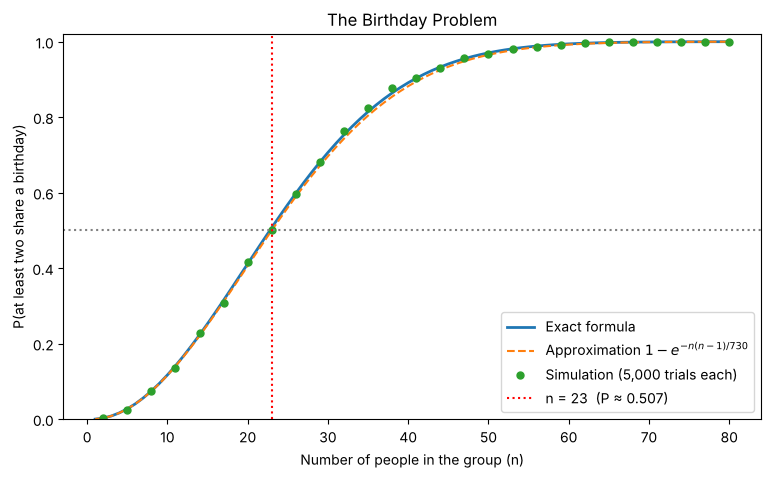

In [8]:
ns = np.arange(1, 81)
exact_curve = [birthday_exact(n) for n in ns]
approx_curve = [birthday_approx(n) for n in ns]
sim_ns = np.arange(2, 81, 3)
sim_curve = [birthday_simulation(n, trials=5_000) for n in sim_ns]

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(ns, exact_curve, lw=2, label="Exact formula")
ax.plot(ns, approx_curve, "--", lw=1.5, label=r"Approximation $1-e^{-n(n-1)/730}$")
ax.plot(sim_ns, sim_curve, "o", ms=5, label="Simulation (5,000 trials each)")
ax.axhline(0.5, color="gray", ls=":")
ax.axvline(23, color="red", ls=":", label="n = 23  (P ≈ 0.507)")
ax.set_xlabel("Number of people in the group (n)")
ax.set_ylabel("P(at least two share a birthday)")
ax.set_title("The Birthday Problem")
ax.set_ylim(0, 1.02)
ax.legend(loc="lower right")
plt.show()

## 5. Convergence of the simulation (n = 23)

As the number of simulated groups increases, the empirical probability approaches the exact value (Law of Large Numbers).

In [9]:
trial_counts = [100, 1_000, 10_000, 100_000]
conv = pd.DataFrame({
    "Simulated groups": trial_counts,
    "Empirical P (n = 23)": [birthday_simulation(23, trials=t) for t in trial_counts],
})
conv["Exact P"] = birthday_exact(23)
conv["Absolute difference"] = (conv["Empirical P (n = 23)"] - conv["Exact P"]).abs()
conv

,Simulated groups,Empirical P (n = 23),Exact P,Absolute difference
0,100,0.5700,0.5073,0.0627
1,1000,0.5000,0.5073,0.0073
2,10000,0.5061,0.5073,0.0012
3,100000,0.5070,0.5073,0.0003


## Conclusions

* The exact probability that at least two of $n$ people share a birthday is $1 - \prod_{k=0}^{n-1}\frac{365-k}{365}$.
* Only **23 people** give a probability above 50 % (0.5073). With 50 people it is 0.970, and with 70 people it is 0.9992.
* The Monte Carlo simulation agrees with the exact formula. With 100,000 groups of 23 it gives 0.5081, compared with 0.5073.
* The result is surprising because the number of **pairs** grows like $n^2/2$: 23 people form 253 pairs. In contrast, a group of 254 people (you plus 253 others) is needed before someone has a better than even chance of sharing **your own** birthday.
* The exponential approximation $1 - e^{-n(n-1)/730}$ is very close to the exact curve.
* Real birthdays are not perfectly uniform across the year. Non-uniform birthdays only make a match **more** likely, so 23 is an upper bound on the group size needed for a 50 % chance.